# Pairwise & Three-Way Analysis: UMAP + DBSCAN Clustering (26 Categories)

Following *Hands-On Machine Learning* (Géron, Ch. 8, Fig. 8-6):
- **Marker shape** = which comparison group (6 groups → 6 shapes: circle, triangle, square, diamond, plus, star)
- **Marker color** = which case within the group (dark = all assays active → light = one assay active)
- DBSCAN **eps** is chosen from a k-distance elbow plot before fitting
- Silhouette score validates cluster quality

| Shape | Group | Source comparison | Cases |
|-------|-------|-------------------|-------|
| ● circle    | G1 | 3-way: Caspase + Mito + Mito Viability   | 7 (excl. both-inactive) |
| ▲ triangle  | G2 | 3-way: Caspase + Mito + Caspase Viability | 7 |
| ■ square    | G3 | Pairwise: Caspase vs Mito (HepG2)         | 3 |
| ◆ diamond   | G4 | Pairwise: Mito vs Mito Viability           | 3 |
| ✚ plus      | G5 | Pairwise: CHO-K1 Caspase vs Viability      | 3 |
| ★ star      | G6 | Pairwise: HepG2 Caspase vs Viability       | 3 |

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import umap
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from collections import Counter, defaultdict
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})
print('Libraries loaded.')

Libraries loaded.


## Step 1 — Build CID → SMILES mapping

In [32]:
BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/cleaned_datasets/'

smiles_map = {}
for fname in ['combined_hepg2_casepase.csv','AID_720635_cleaned.csv',
              'AID_720634_cleaned.csv','AID_1346981_cleaned.csv',
              'AID_1346980_cleaned.csv','AID_1346979_cleaned.csv',
              'AID_1346978_cleaned.csv']:
    try:
        df = pd.read_csv(BASE+fname,
                         usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES'],
                         low_memory=False)
        df = df.dropna(subset=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES'])
        df = df.drop_duplicates('PUBCHEM_CID')
        df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
        smiles_map.update(dict(zip(df['PUBCHEM_CID'], df['PUBCHEM_EXT_DATASOURCE_SMILES'])))
    except Exception as e:
        print(f'  Warning [{fname}]: {e}')

print(f'Total CID->SMILES: {len(smiles_map)}')

Total CID->SMILES: 8777


## Step 2 — Load activity outcome sets

In [33]:
def cids_with(path, outcome):
    df = pd.read_csv(path,
                     usecols=['PUBCHEM_CID','PUBCHEM_ACTIVITY_OUTCOME'],
                     low_memory=False)
    df = df.dropna(subset=['PUBCHEM_CID','PUBCHEM_ACTIVITY_OUTCOME'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    pri = {'Active':2,'Inconclusive':1,'Inactive':0}
    df['_p'] = df['PUBCHEM_ACTIVITY_OUTCOME'].map(pri).fillna(-1)
    df = df.sort_values('_p', ascending=False).drop_duplicates('PUBCHEM_CID')
    return set(df[df['PUBCHEM_ACTIVITY_OUTCOME']==outcome]['PUBCHEM_CID'])

casp_A   = cids_with(BASE+'combined_hepg2_casepase.csv','Active')
casp_I   = cids_with(BASE+'combined_hepg2_casepase.csv','Inactive')
mito_A   = cids_with(BASE+'AID_720635_cleaned.csv','Active')
mito_I   = cids_with(BASE+'AID_720635_cleaned.csv','Inactive')
mviab_A  = cids_with(BASE+'AID_720634_cleaned.csv','Active')
mviab_I  = cids_with(BASE+'AID_720634_cleaned.csv','Inactive')
cviab_A  = cids_with(BASE+'AID_1346981_cleaned.csv','Active')
cviab_I  = cids_with(BASE+'AID_1346981_cleaned.csv','Inactive')
cho_ca_A = cids_with(BASE+'AID_1346980_cleaned.csv','Active')
cho_ca_I = cids_with(BASE+'AID_1346980_cleaned.csv','Inactive')
cho_vi_A = cids_with(BASE+'AID_1346979_cleaned.csv','Active')
cho_vi_I = cids_with(BASE+'AID_1346979_cleaned.csv','Inactive')
hca_A    = cids_with(BASE+'AID_1346978_cleaned.csv','Active')
hca_I    = cids_with(BASE+'AID_1346978_cleaned.csv','Inactive')

print('Activity sets loaded.')

Activity sets loaded.


## Step 3 — Define all 26 categories (both-inactive excluded everywhere)

In [34]:
# (key, group, case_number, short_label, cid_set)
CATEGORIES = [
    # G1: 3-way Caspase + Mito + Mito Viability  (cases 1-7)
    ('G1_C1','G1',1,'Casp+Mito+MitoViab active',        casp_A&mito_A&mviab_A),
    ('G1_C2','G1',2,'Casp+Mito active, MitoViab inact', casp_A&mito_A&mviab_I),
    ('G1_C3','G1',3,'Casp act, Mito-, MitoViab+',       casp_A&mito_I&mviab_A),
    ('G1_C4','G1',4,'Casp act, Mito-, MitoViab-',       casp_A&mito_I&mviab_I),
    ('G1_C5','G1',5,'Casp-, Mito+MitoViab active',      casp_I&mito_A&mviab_A),
    ('G1_C6','G1',6,'Casp-, Mito act, MitoViab-',       casp_I&mito_A&mviab_I),
    ('G1_C7','G1',7,'Casp-Mito-, MitoViab active',      casp_I&mito_I&mviab_A),
    # G2: 3-way Caspase + Mito + Caspase Viability  (cases 1-7)
    ('G2_C1','G2',1,'Casp+Mito+CaspViab active',        casp_A&mito_A&cviab_A),
    ('G2_C2','G2',2,'Casp+Mito active, CaspViab inact', casp_A&mito_A&cviab_I),
    ('G2_C3','G2',3,'Casp+CaspViab active, Mito-',      casp_A&mito_I&cviab_A),
    ('G2_C4','G2',4,'Casp act, Mito-, CaspViab-',       casp_A&mito_I&cviab_I),
    ('G2_C5','G2',5,'Casp-, Mito+CaspViab active',      casp_I&mito_A&cviab_A),
    ('G2_C6','G2',6,'Casp-, Mito act, CaspViab-',       casp_I&mito_A&cviab_I),
    ('G2_C7','G2',7,'Casp-Mito-, CaspViab active',      casp_I&mito_I&cviab_A),
    # G3: Pairwise Caspase vs Mito  (3 cases)
    ('G3_C1','G3',1,'Casp+Mito both active',             casp_A&mito_A),
    ('G3_C2','G3',2,'Casp active, Mito inactive',        casp_A&mito_I),
    ('G3_C3','G3',3,'Casp inactive, Mito active',        casp_I&mito_A),
    # G4: Pairwise Mito vs Mito Viability  (3 cases)
    ('G4_C1','G4',1,'Mito+MitoViab both active',         mito_A&mviab_A),
    ('G4_C2','G4',2,'Mito active, MitoViab inactive',    mito_A&mviab_I),
    ('G4_C3','G4',3,'Mito inactive, MitoViab active',    mito_I&mviab_A),
    # G5: Pairwise CHO-K1 Caspase vs Viability  (3 cases)
    ('G5_C1','G5',1,'CHO-K1: Casp+Viab both active',    cho_ca_A&cho_vi_A),
    ('G5_C2','G5',2,'CHO-K1: Casp act, Viab inact',     cho_ca_A&cho_vi_I),
    ('G5_C3','G5',3,'CHO-K1: Casp inact, Viab act',     cho_ca_I&cho_vi_A),
    # G6: Pairwise HepG2 Caspase vs Viability  (3 cases)
    ('G6_C1','G6',1,'HepG2: Casp+Viab both active',     hca_A&cviab_A),
    ('G6_C2','G6',2,'HepG2: Casp act, Viab inact',      hca_A&cviab_I),
    ('G6_C3','G6',3,'HepG2: Casp inact, Viab act',      hca_I&cviab_A),
]

print(f'{'Key':8s}  {'n':>6s}  Label')
print('-'*65)
for key,grp,case,lbl,cids in CATEGORIES:
    print(f'{key:8s}  {len(cids):>6d}  {lbl}')
print('-'*65)
print(f'Total unique CIDs: {len(set().union(*[c for *_,c in CATEGORIES]))}')

Key            n  Label
-----------------------------------------------------------------
G1_C1         63  Casp+Mito+MitoViab active
G1_C2         43  Casp+Mito active, MitoViab inact
G1_C3          0  Casp act, Mito-, MitoViab+
G1_C4         17  Casp act, Mito-, MitoViab-
G1_C5        168  Casp-, Mito+MitoViab active
G1_C6        484  Casp-, Mito act, MitoViab-
G1_C7          0  Casp-Mito-, MitoViab active
G2_C1        101  Casp+Mito+CaspViab active
G2_C2         11  Casp+Mito active, CaspViab inact
G2_C3          6  Casp+CaspViab active, Mito-
G2_C4          5  Casp act, Mito-, CaspViab-
G2_C5        179  Casp-, Mito+CaspViab active
G2_C6        550  Casp-, Mito act, CaspViab-
G2_C7         17  Casp-Mito-, CaspViab active
G3_C1        144  Casp+Mito both active
G3_C2         17  Casp active, Mito inactive
G3_C3        972  Casp inactive, Mito active
G4_C1        293  Mito+MitoViab both active
G4_C2        680  Mito active, MitoViab inactive
G4_C3          0  Mito inactive, MitoViab 

## Step 4 — Assign primary label (G1>G2>G3>G4>G5>G6, lower case = higher priority)

In [35]:
cid_meta = {}  # CID -> (key, grp, case, lbl)
for key,grp,case,lbl,cids in CATEGORIES:
    for cid in cids:
        if cid not in cid_meta:
            cid_meta[cid] = (key, grp, case, lbl)

cnt = Counter(v[0] for v in cid_meta.values())
print('Primary label distribution:')
for key,grp,case,lbl,_ in CATEGORIES:
    if cnt[key]:
        print(f'  {key:8s}  n={cnt[key]}')

Primary label distribution:
  G1_C1     n=63
  G1_C2     n=43
  G1_C4     n=17
  G1_C5     n=168
  G1_C6     n=484
  G2_C1     n=26
  G2_C2     n=1
  G2_C5     n=55
  G2_C6     n=175
  G2_C7     n=17
  G3_C1     n=11
  G3_C3     n=90
  G4_C1     n=62
  G4_C2     n=153
  G5_C1     n=42
  G5_C3     n=430
  G6_C1     n=14
  G6_C2     n=7
  G6_C3     n=8


## Step 5 — Compute Morgan fingerprints (radius=2, 2048-bit)

In [36]:
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

valid_cids, valid_keys, valid_grps, valid_cases = [], [], [], []
fps_list = []

for cid,(key,grp,case,lbl) in cid_meta.items():
    smi = smiles_map.get(cid)
    if not smi or pd.isna(smi): continue
    mol = Chem.MolFromSmiles(str(smi))
    if mol is None: continue
    valid_cids.append(cid)
    valid_keys.append(key)
    valid_grps.append(grp)
    valid_cases.append(case)
    fps_list.append(gen.GetFingerprintAsNumPy(mol))

fps         = np.array(fps_list, dtype=np.uint8)
valid_keys  = np.array(valid_keys)
valid_grps  = np.array(valid_grps)
valid_cases = np.array(valid_cases)

print(f'Valid compounds: {len(valid_cids)}')
print(f'FP matrix shape: {fps.shape}')

Valid compounds: 1866
FP matrix shape: (1866, 2048)


[17:16:01] WARNING: not removing hydrogen atom without neighbors
[17:16:01] WARNING: not removing hydrogen atom without neighbors


## Step 6 — UMAP (Jaccard / Tanimoto distance on binary fingerprints)

In [37]:
print('Running UMAP...')
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1,
                    metric='jaccard', random_state=42, n_jobs=1)
embedding = reducer.fit_transform(fps)
print(f'Embedding shape: {embedding.shape}')

Running UMAP...
Embedding shape: (1866, 2)


## Step 7 — k-distance elbow plot to choose DBSCAN eps

Sort all points by their k-th nearest-neighbour distance (ascending).  
The sharp bend (elbow) marks the natural density threshold — use that as `eps`.

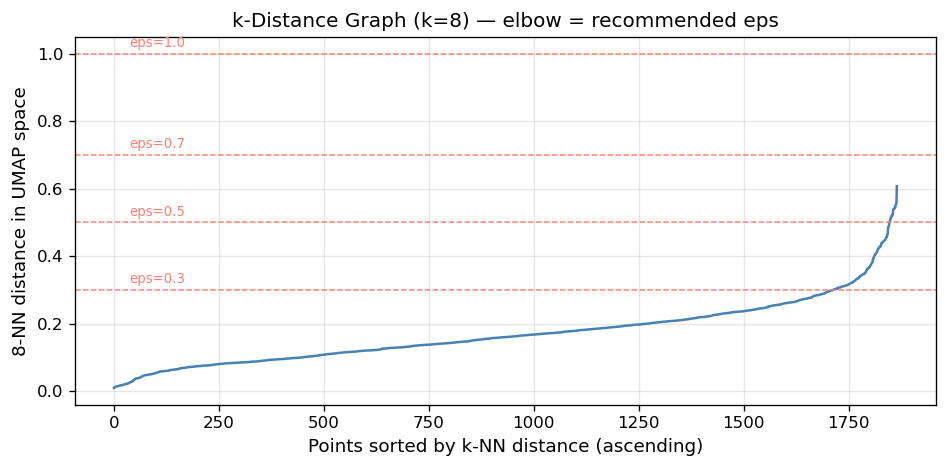

In [38]:
K = 8
nbrs = NearestNeighbors(n_neighbors=K, metric='euclidean').fit(embedding)
dist, _ = nbrs.kneighbors(embedding)
k_dist  = np.sort(dist[:, K-1])  # ascending

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_dist, color='steelblue', linewidth=1.5)
ax.set_xlabel('Points sorted by k-NN distance (ascending)', fontsize=11)
ax.set_ylabel(f'{K}-NN distance in UMAP space', fontsize=11)
ax.set_title(f'k-Distance Graph (k={K}) — elbow = recommended eps', fontsize=12)
ax.grid(True, alpha=0.3)
for eps_c in [0.3, 0.5, 0.7, 1.0]:
    ax.axhline(eps_c, color='salmon', linestyle='--', lw=0.9)
    ax.text(len(k_dist)*0.02, eps_c+0.02, f'eps={eps_c}', fontsize=8, color='salmon')
plt.tight_layout()
plt.savefig('/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/umap_kdist_elbow.png',
            dpi=130, bbox_inches='tight')
plt.show()

## Step 8 — Fit DBSCAN and evaluate with silhouette score

In [ ]:
EPS         = 0.3   
MIN_SAMPLES = 5

db        = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
db_labels = db.fit_predict(embedding)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise    = (db_labels == -1).sum()
print(f'eps={EPS}, min_samples={MIN_SAMPLES}')
print(f'Clusters : {n_clusters}')
print(f'Noise    : {n_noise} ({100*n_noise/len(db_labels):.1f}%)')

ok = db_labels >= 0
if ok.sum() > 1 and n_clusters > 1:
    sil = silhouette_score(embedding[ok], db_labels[ok])
    print(f'Silhouette score (non-noise): {sil:.3f}  [-1 to +1, higher = better-defined clusters]')

eps=0.3, min_samples=5
Clusters : 29
Noise    : 19 (1.0%)
Silhouette score (non-noise): -0.041  [-1 to +1, higher = better-defined clusters]


## Step 9 — Define marker shapes (one per group) and color palette (dark→light per group)

In [40]:
# Marker shapes — one per group (as in Géron Fig. 8-6: triangles vs squares)
MARKERS = {'G1':'o', 'G2':'^', 'G3':'s', 'G4':'D', 'G5':'P', 'G6':'*'}
MARKER_NAMES = {
    'G1':'circle  ●',  'G2':'triangle ▲', 'G3':'square  ■',
    'G4':'diamond ◆', 'G5':'plus    ✚',  'G6':'star    ★'
}
GROUP_LABELS = {
    'G1':'G1: 3-way Casp+Mito+MitoViab',
    'G2':'G2: 3-way Casp+Mito+CaspViab',
    'G3':'G3: Pairwise Casp vs Mito',
    'G4':'G4: Pairwise Mito vs MitoViab',
    'G5':'G5: Pairwise CHO-K1 Casp vs Viab',
    'G6':'G6: Pairwise HepG2 Casp vs Viab',
}

# Color palettes — dark (case 1 = all active) → light (highest case = fewest active)
GROUP_CMAPS = {'G1':plt.cm.Blues, 'G2':plt.cm.Reds,
               'G3':plt.cm.Greens, 'G4':plt.cm.Purples,
               'G5':plt.cm.Oranges, 'G6':plt.cm.GnBu}

grp_max_case = defaultdict(int)
for _,grp,case,*_ in CATEGORIES:
    grp_max_case[grp] = max(grp_max_case[grp], case)

CAT_COLOR = {}
for key,grp,case,*_ in CATEGORIES:
    nmax  = grp_max_case[grp]
    shade = 0.88 - (case-1)/max(nmax-1,1) * 0.55  # 0.88 (dark) to 0.33 (light)
    CAT_COLOR[key] = GROUP_CMAPS[grp](shade)

print('Shape and color mapping defined.')
for g,m in MARKERS.items():
    print(f'  {MARKER_NAMES[g]:16s}  {GROUP_LABELS[g]}')

Shape and color mapping defined.
  circle  ●         G1: 3-way Casp+Mito+MitoViab
  triangle ▲        G2: 3-way Casp+Mito+CaspViab
  square  ■         G3: Pairwise Casp vs Mito
  diamond ◆         G4: Pairwise Mito vs MitoViab
  plus    ✚         G5: Pairwise CHO-K1 Casp vs Viab
  star    ★         G6: Pairwise HepG2 Casp vs Viab


## Step 10 — Figure A: UMAP — 26 categories (shape = group, color = case)

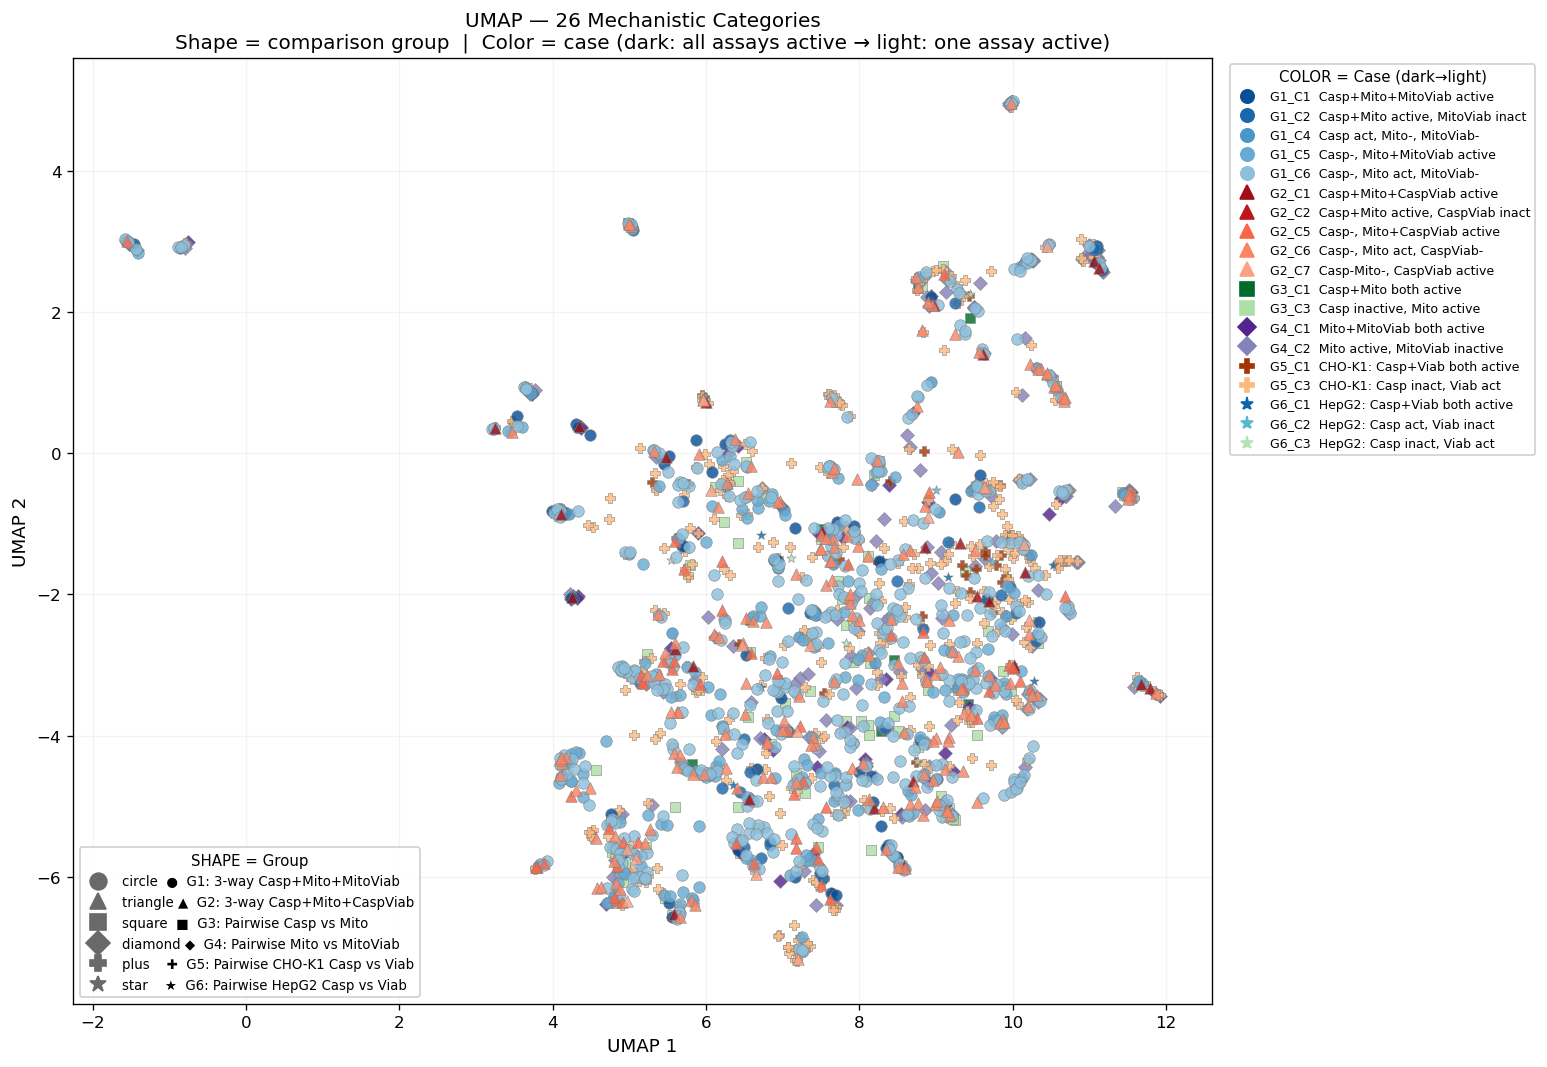

Saved: umap_26cat_shape_color.png


In [41]:
fig, ax = plt.subplots(figsize=(13, 9))

for key,grp,case,lbl,_ in CATEGORIES:
    mask = valid_keys == key
    n    = mask.sum()
    if n == 0: continue
    ax.scatter(
        embedding[mask,0], embedding[mask,1],
        marker=MARKERS[grp], color=CAT_COLOR[key],
        s=48 if grp in ('G1','G2') else 35,
        alpha=0.82, linewidths=0.4, edgecolors='grey',
        zorder=4 if grp in ('G1','G2') else 2,
        label=f'{key} (n={n})',
    )

ax.set_title(
    'UMAP — 26 Mechanistic Categories\n'
    'Shape = comparison group  |  Color = case (dark: all assays active → light: one assay active)',
    fontsize=12
)
ax.set_xlabel('UMAP 1', fontsize=11)
ax.set_ylabel('UMAP 2', fontsize=11)
ax.grid(True, alpha=0.15)

# Legend A: shape = group
sh = [mlines.Line2D([0],[0], marker=MARKERS[g], color='dimgrey',
                    linestyle='None', markersize=10,
                    label=f'{MARKER_NAMES[g]}  {GROUP_LABELS[g]}')
      for g in ['G1','G2','G3','G4','G5','G6']]
leg1 = ax.legend(handles=sh, title='SHAPE = Group',
                 loc='lower left', fontsize=8, title_fontsize=9,
                 framealpha=0.92, ncol=1)
ax.add_artist(leg1)

# Legend B: color = category key
ch = [mlines.Line2D([0],[0], marker=MARKERS[grp], color=CAT_COLOR[key],
                    linestyle='None', markersize=8,
                    label=f'{key}  {lbl}')
      for key,grp,case,lbl,_ in CATEGORIES
      if (valid_keys==key).sum() > 0]
ax.legend(handles=ch, title='COLOR = Case (dark→light)',
          bbox_to_anchor=(1.01,1), loc='upper left',
          fontsize=7.5, title_fontsize=9, framealpha=0.92, ncol=1)

plt.tight_layout()
plt.savefig('/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/umap_26cat_shape_color.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: umap_26cat_shape_color.png')

## Step 11 — Figure B: UMAP — DBSCAN clusters (shape=group, color=cluster)

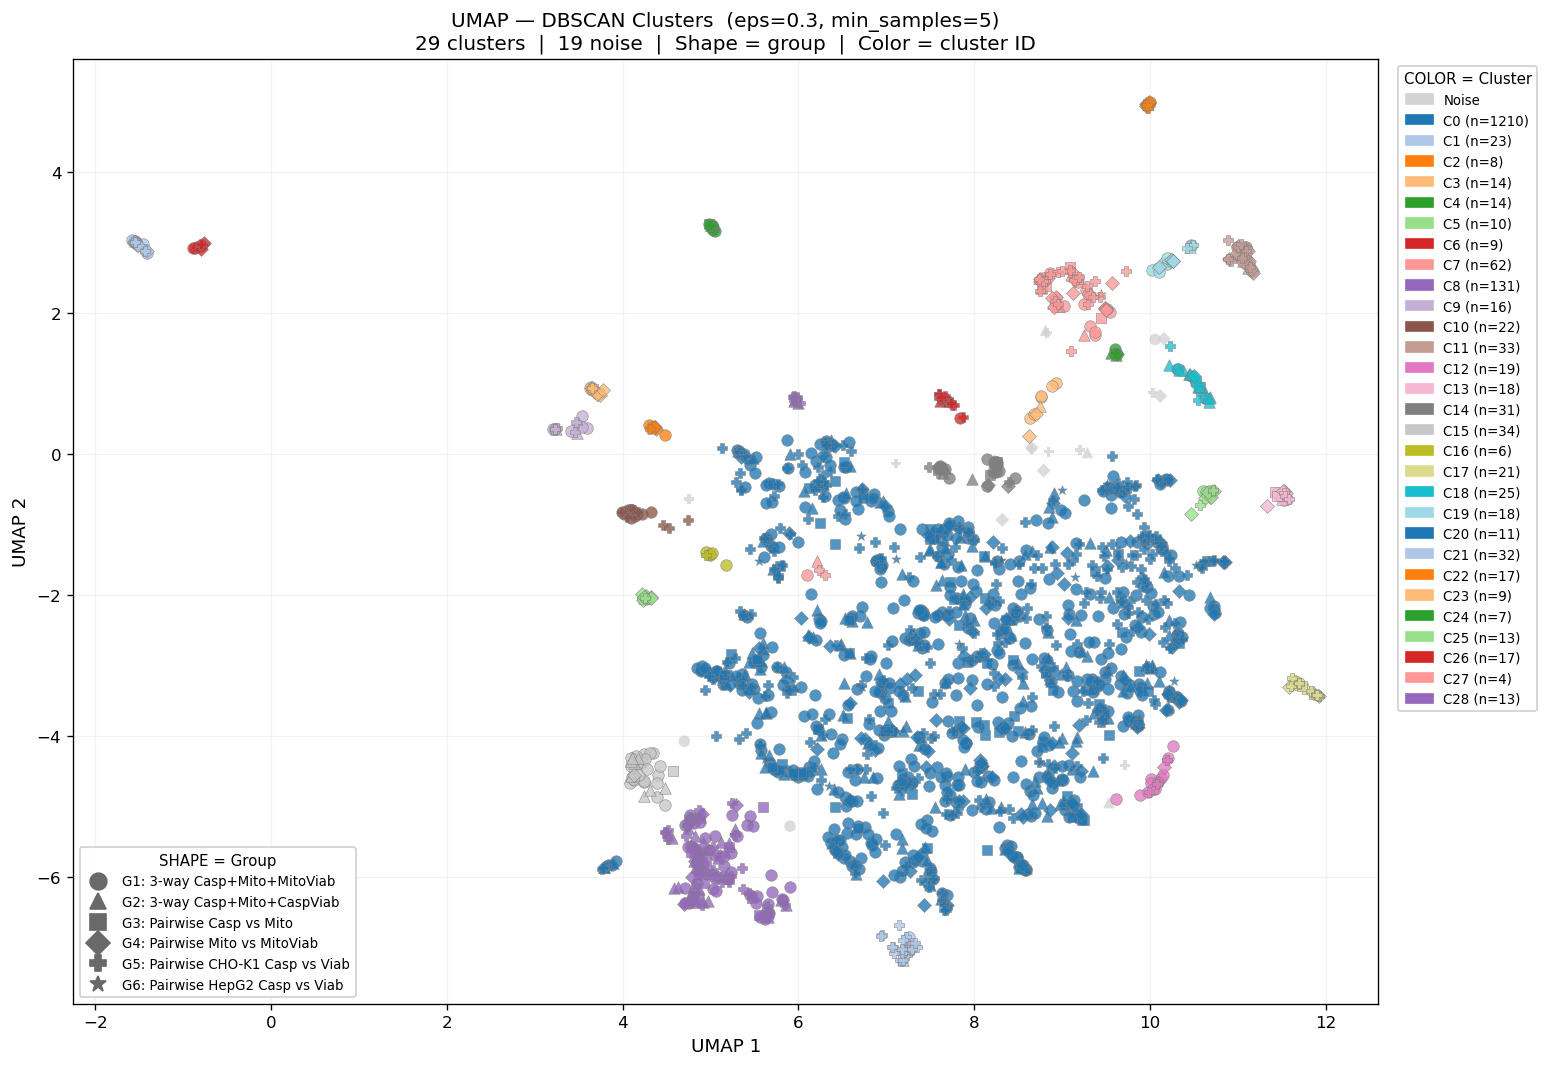

Saved: umap_dbscan_shape_color.png


In [42]:
cmap_db     = plt.cm.tab20
cluster_ids = sorted(set(db_labels))

fig, ax = plt.subplots(figsize=(13, 9))

for cl in cluster_ids:
    color = 'lightgrey' if cl == -1 else cmap_db(cl % 20)
    for grp, mkr in MARKERS.items():
        sub = (db_labels==cl) & (valid_grps==grp)
        if sub.sum() == 0: continue
        lbl_str = ('Noise' if cl==-1 else f'Cluster {cl} (n={(db_labels==cl).sum()})')
        ax.scatter(
            embedding[sub,0], embedding[sub,1],
            marker=mkr, color=color,
            s=48 if grp in ('G1','G2') else 35,
            alpha=0.78, linewidths=0.4,
            edgecolors='grey' if cl != -1 else 'none',
            label=lbl_str if grp=='G1' else '_nolegend_',
        )

ax.set_title(
    f'UMAP — DBSCAN Clusters  (eps={EPS}, min_samples={MIN_SAMPLES})\n'
    f'{n_clusters} clusters  |  {n_noise} noise  |  '
    'Shape = group  |  Color = cluster ID',
    fontsize=12
)
ax.set_xlabel('UMAP 1', fontsize=11)
ax.set_ylabel('UMAP 2', fontsize=11)
ax.grid(True, alpha=0.15)

sh = [mlines.Line2D([0],[0], marker=MARKERS[g], color='dimgrey',
                    linestyle='None', markersize=10, label=GROUP_LABELS[g])
      for g in ['G1','G2','G3','G4','G5','G6']]
leg1 = ax.legend(handles=sh, title='SHAPE = Group',
                 loc='lower left', fontsize=8, title_fontsize=9, framealpha=0.92)
ax.add_artist(leg1)

cl_h = [mpatches.Patch(color='lightgrey' if cl==-1 else cmap_db(cl%20),
                        label='Noise' if cl==-1 else f'C{cl} (n={(db_labels==cl).sum()})')
        for cl in cluster_ids]
ax.legend(handles=cl_h, title='COLOR = Cluster',
          bbox_to_anchor=(1.01,1), loc='upper left',
          fontsize=8, title_fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.savefig('/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/umap_dbscan_shape_color.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: umap_dbscan_shape_color.png')

## Step 12 — Figure C: Side-by-side panel

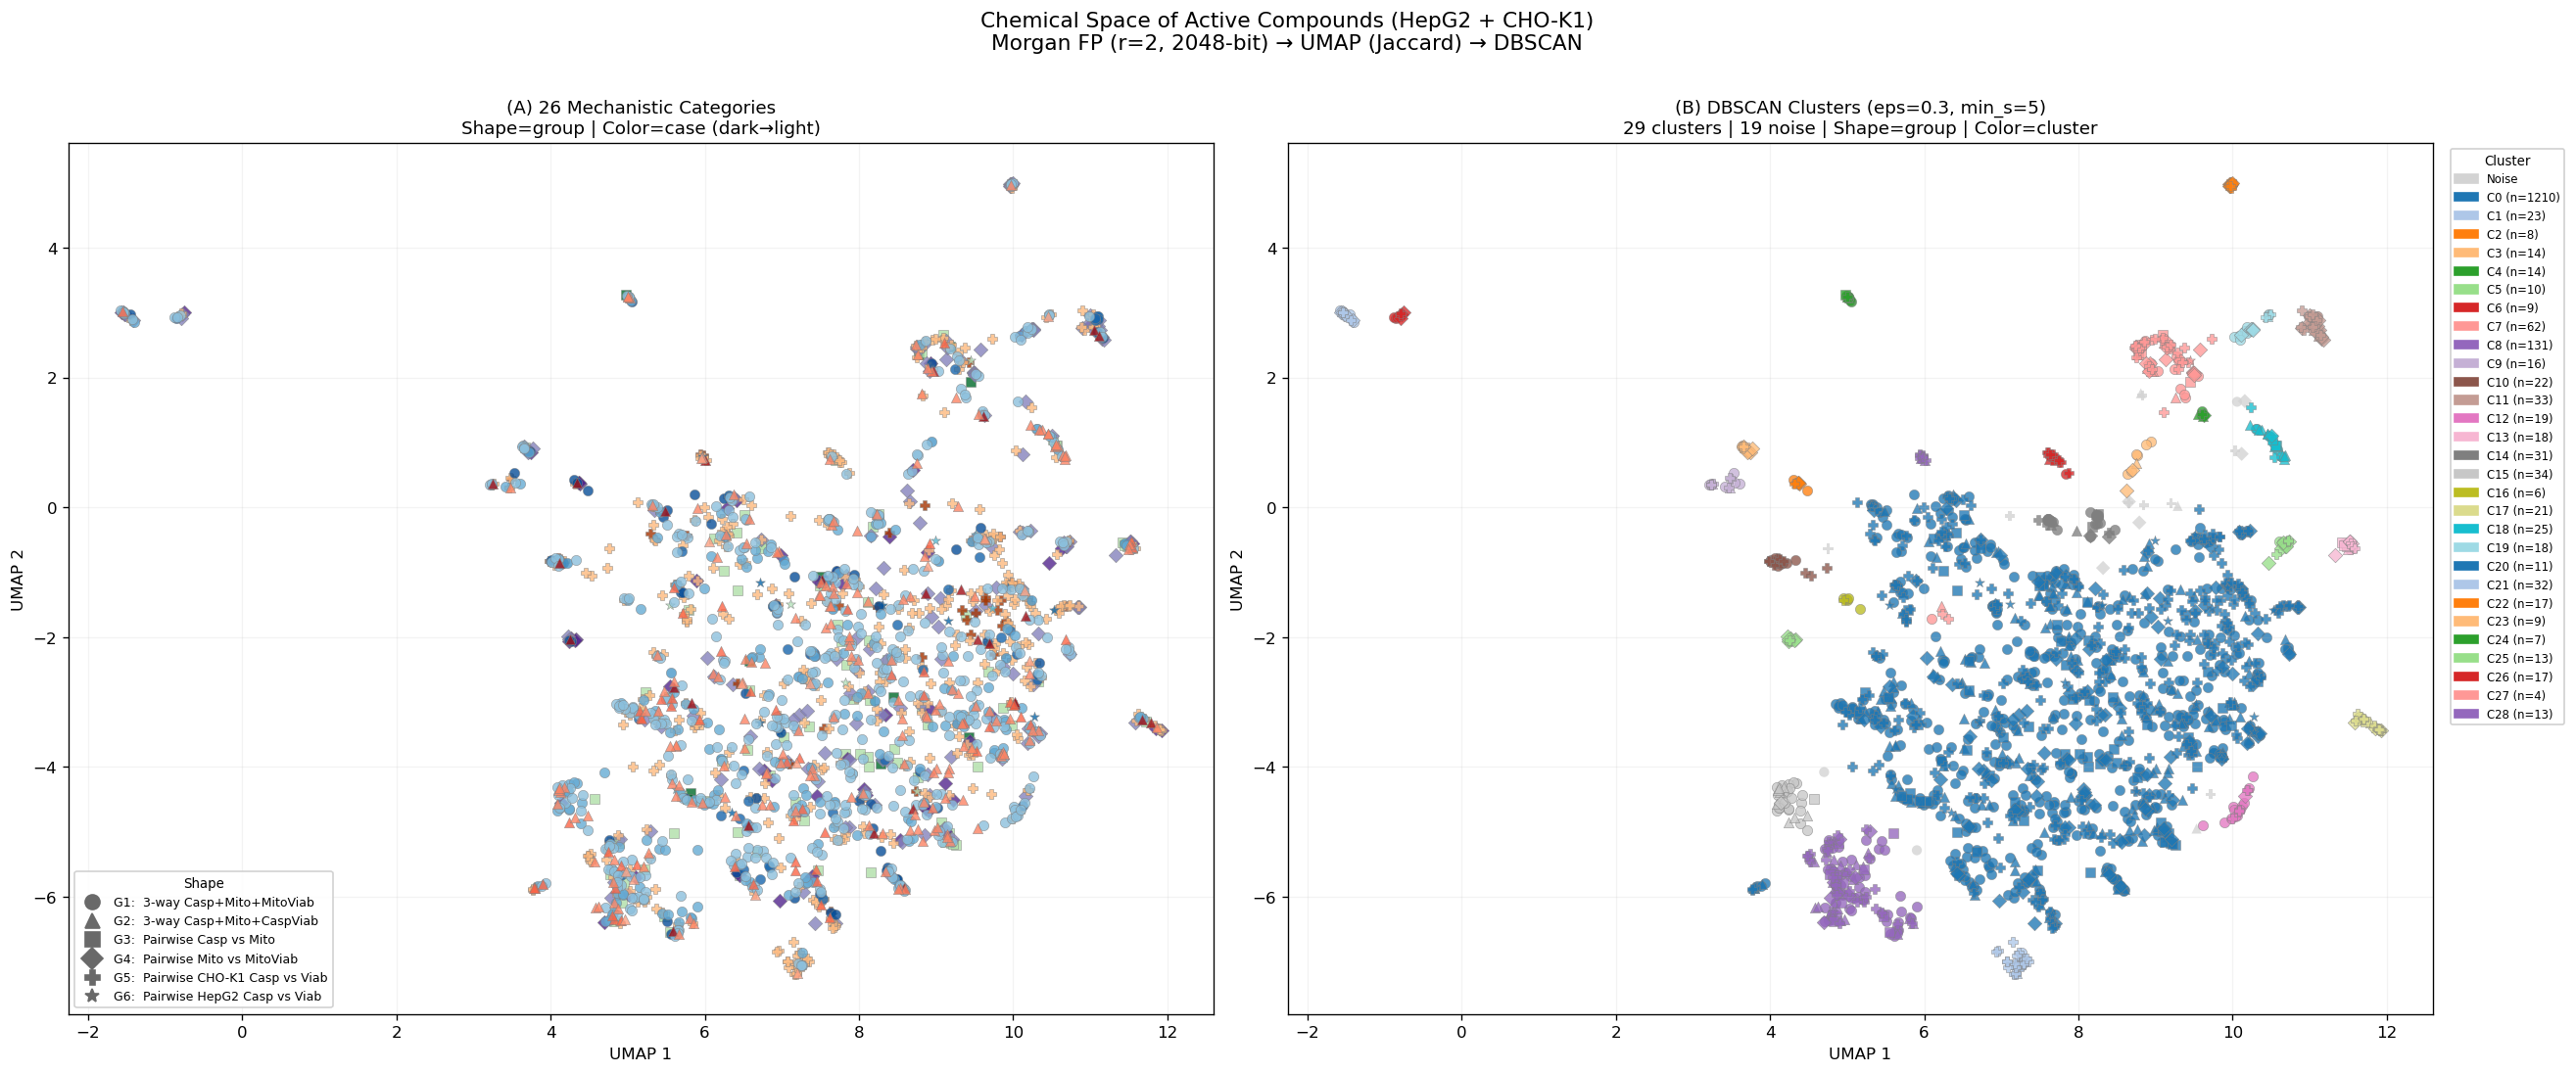

Saved: umap_panel_shapes.png


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# Left: 26 categories
ax1 = axes[0]
for key,grp,case,lbl,_ in CATEGORIES:
    mask = valid_keys==key
    if mask.sum()==0: continue
    ax1.scatter(embedding[mask,0], embedding[mask,1],
                marker=MARKERS[grp], color=CAT_COLOR[key],
                s=38, alpha=0.80, linewidths=0.35, edgecolors='grey',
                zorder=4 if grp in ('G1','G2') else 2)
ax1.set_title('(A) 26 Mechanistic Categories\nShape=group | Color=case (dark→light)', fontsize=11)
ax1.set_xlabel('UMAP 1'); ax1.set_ylabel('UMAP 2')
ax1.grid(True, alpha=0.15)
sh = [mlines.Line2D([0],[0], marker=MARKERS[g], color='dimgrey',
                    linestyle='None', markersize=9, label=g+': '+GROUP_LABELS[g].split(':')[1])
      for g in MARKERS]
ax1.legend(handles=sh, title='Shape', loc='lower left',
           fontsize=7.5, title_fontsize=8, framealpha=0.88)

# Right: DBSCAN clusters
ax2 = axes[1]
for cl in cluster_ids:
    color = 'lightgrey' if cl==-1 else cmap_db(cl%20)
    for grp,mkr in MARKERS.items():
        sub = (db_labels==cl)&(valid_grps==grp)
        if sub.sum()==0: continue
        ax2.scatter(embedding[sub,0], embedding[sub,1],
                    marker=mkr, color=color,
                    s=38, alpha=0.78, linewidths=0.35,
                    edgecolors='grey' if cl!=-1 else 'none')
ax2.set_title(f'(B) DBSCAN Clusters (eps={EPS}, min_s={MIN_SAMPLES})\n'
              f'{n_clusters} clusters | {n_noise} noise | Shape=group | Color=cluster',
              fontsize=11)
ax2.set_xlabel('UMAP 1'); ax2.set_ylabel('UMAP 2')
ax2.grid(True, alpha=0.15)
cl_h = [mpatches.Patch(color='lightgrey' if cl==-1 else cmap_db(cl%20),
                        label='Noise' if cl==-1 else f'C{cl} (n={(db_labels==cl).sum()})')
        for cl in cluster_ids]
ax2.legend(handles=cl_h, title='Cluster', bbox_to_anchor=(1.01,1), loc='upper left',
           fontsize=7, title_fontsize=8, framealpha=0.9, ncol=1)

plt.suptitle('Chemical Space of Active Compounds (HepG2 + CHO-K1)\n'
             'Morgan FP (r=2, 2048-bit) → UMAP (Jaccard) → DBSCAN',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/umap_panel_shapes.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: umap_panel_shapes.png')

## Step 13 — Cluster composition and enrichment table

In [44]:
df_res = pd.DataFrame({
    'CID':    valid_cids,
    'Key':    valid_keys,
    'Group':  valid_grps,
    'Case':   valid_cases,
    'DBSCAN': db_labels,
    'UMAP1':  embedding[:,0],
    'UMAP2':  embedding[:,1],
})

comp = df_res.groupby(['DBSCAN','Group']).size().unstack(fill_value=0)
comp.index = ['Noise' if i==-1 else f'C{i}' for i in comp.index]
print('Cluster × Group composition:')
print(comp.to_string())

print('\nCluster enrichment (≥5 members):')
print(f'{'Cluster':10s}  {'n':>5s}  {'Dom.Key':8s}  {'%':>5s}  Interpretation')
print('─'*72)
lbl_map = {key:lbl for key,*_,lbl,_ in CATEGORIES}
for cl in sorted(set(db_labels)):
    sub = df_res[df_res['DBSCAN']==cl]
    if len(sub)<5: continue
    top = sub['Key'].value_counts()
    dom_key = top.index[0]; dom_n = top.iloc[0]; frac = dom_n/len(sub)
    flag = '  *** ENRICHED' if frac>0.6 else ''
    cl_nm = 'Noise' if cl==-1 else f'Cluster {cl}'
    print(f'{cl_nm:10s}  {len(sub):>5d}  {dom_key:8s}  {frac:>4.0%}  {lbl_map.get(dom_key,"")[:35]}{flag}')

df_res.to_csv('/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/umap_cluster_assignments.csv', index=False)
print('\nSaved: umap_cluster_assignments.csv')

Cluster × Group composition:
Group   G1   G2  G3   G4   G5  G6
Noise    3    3   0    5    8   0
C0     518  184  73  117  294  24
C1      14    1   0    5    3   0
C2       3    1   0    3    1   0
C3       7    0   1    5    1   0
C4       9    3   1    0    1   0
C5       2    1   0    6    1   0
C6       4    0   0    3    2   0
C7      13    7   5   16   20   1
C8      61   23   9    8   27   3
C9       7    2   0    0    7   0
C10     12    1   0    0    9   0
C11     10    2   0   12    9   0
C12     12    0   0    1    6   0
C13      4    4   3    4    3   0
C14     20    4   2    2    3   0
C15     24    8   1    1    0   0
C16      5    0   0    0    1   0
C17      3    3   1    3   11   0
C18      7   12   3    1    2   0
C19     10    1   0    5    2   0
C20      3    4   0    0    4   0
C21      4    1   0    0   27   0
C22      4    1   1    9    2   0
C23      6    1   0    2    0   0
C24      3    2   0    1    1   0
C25      4    0   0    6    3   0
C26      2    1   1

## Step 14 — Legend card (shape + color reference)

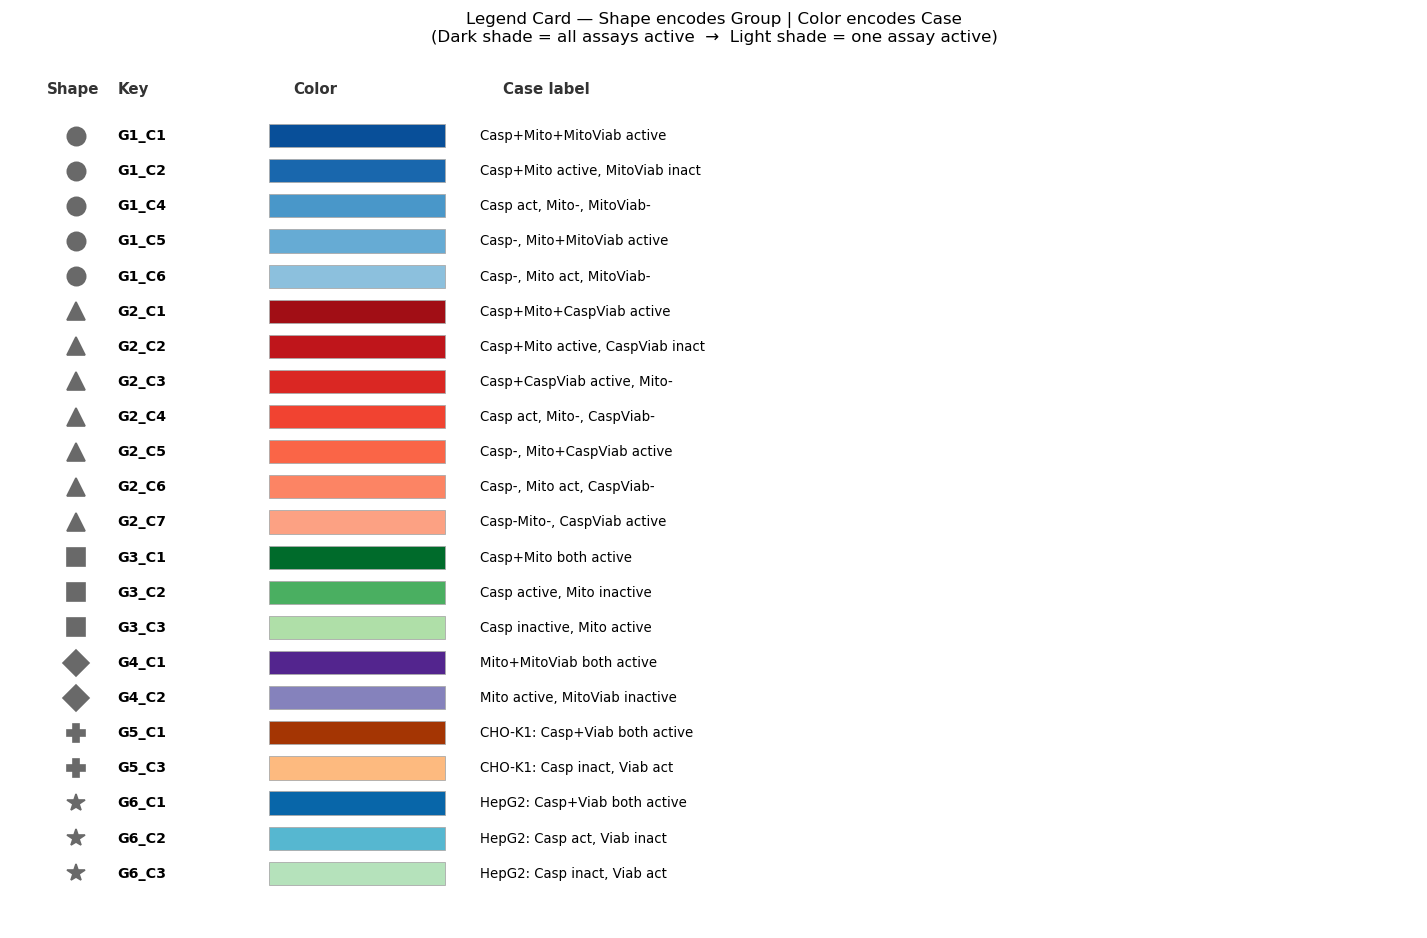

Saved: umap_legend_card.png


In [45]:
present = [(key,grp,case,lbl,CAT_COLOR[key])
           for key,grp,case,lbl,cids in CATEGORIES if len(cids)>0]

fig, ax = plt.subplots(figsize=(12, max(7, len(present)*0.36)))
ax.set_xlim(0,12); ax.set_ylim(-0.5, len(present)+2); ax.axis('off')

# Column headers
for x,txt in zip([0.3,0.9,2.4,4.2], ['Shape','Key','Color','Case label']):
    ax.text(x, len(present)+1.2, txt, fontsize=9, fontweight='bold', color='#333')

for i,(key,grp,case,lbl,color) in enumerate(present):
    y = len(present)-i
    ax.plot(0.55, y, marker=MARKERS[grp], color='dimgrey', markersize=11, linestyle='None')
    ax.text(0.9,  y, key,  va='center', fontsize=8.5, fontweight='bold')
    ax.add_patch(plt.Rectangle((2.2,y-0.33),1.5,0.66, color=color, ec='#aaa', lw=0.5))
    ax.text(4.0,  y, lbl,  va='center', fontsize=8)

ax.set_title('Legend Card — Shape encodes Group | Color encodes Case\n'
             '(Dark shade = all assays active  →  Light shade = one assay active)',
             fontsize=10, pad=14)
plt.tight_layout()
plt.savefig('/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/umap_legend_card.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: umap_legend_card.png')